# Comparación final y diagnóstico de la destilación

Reúne los runs registrados y responde si la destilación sirvió: no solo si el macro-F1 subió, sino dónde cambió y por qué. De aquí también sale el modelo que sirve el sitio, porque es el único notebook que los ve todos. Corre en local: baja los pesos de los releases y necesita el corpus en disco.


In [12]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /Users/cristiansandoval/Universidad/Semillero/ButterflyModeling


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scripts import corpus, evalStats
from scripts import modelRegistry as registro
from scripts.vizStyle import INK_MUTED, SERIE_1, SERIE_2, SERIE_3, applyStyle

FIGURAS = registro.OUTPUTS_DIR / "figuras"
FIGURAS.mkdir(exist_ok=True)


## 1 · Todos los runs

In [14]:
CORPUS = corpus.manifiesto()["creado"]

filas = []
for run in registro.listRuns():
    if run.get("dataset") != CORPUS:
        continue
    print(f"Procesando run_id={run['run_id']}...")
    modelo = registro.modeloInferencia(run["run_id"])
    latencia, desviacion = evalStats.medirLatencia(modelo)
    prueba = registro.loadRunMetrics(run["run_id"])["splits"]["test"]
    accBajo, accAlto = evalStats.intervaloWilson(
        round(prueba["accuracy"] * prueba["num_samples"]), prueba["num_samples"])
    f1Bajo, f1Alto = evalStats.bootstrapMacroF1(prueba["y_true"], prueba["y_pred"])
    filas.append({
        "tipo": "destilado" if run.get("distillation") else "base",
        "destilacion": run.get("distillation") or "",
        "T": run.get("temperatura"),
        "alfa": run.get("alfa"),
        "arquitectura": run["architecture"],
        "test_macro_f1": run["test_macro_f1"],
        "validate_macro_f1": run["validate_macro_f1"],
        "f1_ic95": f"[{f1Bajo:.4f}, {f1Alto:.4f}]",
        "test_accuracy": run["test_accuracy"],
        "acc_ic95": f"[{accBajo:.4f}, {accAlto:.4f}]",
        "parametros_M": round(modelo.count_params() / 1e6, 2),
        "pesos_MB": round(modelo.count_params() * 4 / 1e6, 1),
        "latencia_ms": round(latencia, 1),
        "latencia_sd_ms": round(desviacion, 1),
        "minutos": run["training_minutes"],
        "run_id": run["run_id"],
    })

todos = pd.DataFrame(filas).sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
todos.drop(columns="run_id")

Procesando run_id=20261024T003138Z_kd-atencion-t2-a30-b40-mobilenet-v3-small...


/opt/miniconda3/envs/semillero/lib/python3.12/site-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Procesando run_id=20261023T020539Z_kd-atencion-t2-a70-b40-mobilenet-v3-small...
Procesando run_id=20261021T203700Z_kd-respuesta-t2-a30-mobilenet-v3-small...
Procesando run_id=20261021T153951Z_kd-respuesta-t2-a70-mobilenet-v3-small...
Procesando run_id=20261017T034621Z_kd-respuesta-ft-mobilenet-v3-small...
Procesando run_id=20261017T032623Z_kd-atencion-mobilenet-v3-small...
Procesando run_id=20261010T000615Z_inception-v3...
Procesando run_id=20261010T000512Z_densenet121...
Procesando run_id=20261008T132019Z_resnet50-v2...
Procesando run_id=20261008T000002Z_efficientnet-v2-b0...
Procesando run_id=20261007T214907Z_nasnet-mobile...
Procesando run_id=20261007T192046Z_efficientnet-b0...
Procesando run_id=20261007T191848Z_mobilenet-v2...


/Users/cristiansandoval/Universidad/Semillero/ButterflyModeling/scripts/architectures.py:61: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = baseClass(weights="imagenet", include_top=False, input_tensor=tensor)


Procesando run_id=20261007T141912Z_efficientnet-v2-s...
Procesando run_id=20261007T124302Z_mobilenet-v3-small...


,tipo,destilacion,T,alfa,arquitectura,test_macro_f1,validate_macro_f1,f1_ic95,test_accuracy,acc_ic95,parametros_M,pesos_MB,latencia_ms,latencia_sd_ms,minutos
0,base,,NaN,NaN,efficientnet_b0,0.943134,0.942410,"[0.9362, 0.9488]",0.944631,"[0.9380, 0.9506]",4.89,19.5,149.6,34.6,193.6
1,base,,NaN,NaN,efficientnet_v2_b0,0.938838,0.934114,"[0.9316, 0.9446]",0.939885,"[0.9330, 0.9461]",6.76,27.0,143.9,2.9,169.3
2,base,,NaN,NaN,efficientnet_v2_s,0.938738,0.937357,"[0.9314, 0.9445]",0.940281,"[0.9334, 0.9465]",21.17,84.7,335.7,18.9,231.8
3,base,,NaN,NaN,inception_v3,0.930419,0.933359,"[0.9228, 0.9365]",0.931975,"[0.9247, 0.9386]",23.03,92.1,204.4,3.2,258.7
4,base,,NaN,NaN,densenet121,0.929776,0.928433,"[0.9221, 0.9359]",0.930987,"[0.9237, 0.9377]",7.74,31.0,272.8,7.7,328.4
5,base,,NaN,NaN,resnet50_v2,0.925146,0.925214,"[0.9174, 0.9315]",0.926241,"[0.9187, 0.9331]",24.79,99.2,188.6,3.3,272.5
6,base,,NaN,NaN,mobilenet_v2,0.913191,0.905801,"[0.9046, 0.9201]",0.914772,"[0.9068, 0.9222]",3.09,12.4,88.7,9.0,145.8
7,destilado,respuesta,2.0,0.3,mobilenet_v3_small,0.910695,0.905694,"[0.9021, 0.9174]",0.912596,"[0.9045, 0.9201]",1.42,5.7,61.3,10.7,240.8
8,destilado,atencion,2.0,0.3,mobilenet_v3_small,0.910247,0.905260,"[0.9020, 0.9173]",0.912003,"[0.9039, 0.9195]",1.42,5.7,57.2,4.8,228.8
9,base,,NaN,NaN,mobilenet_v3_small,0.904865,0.903339,"[0.8963, 0.9120]",0.906466,"[0.8981, 0.9142]",1.42,5.7,55.0,1.3,80.8


## 2 · Calidad vs costo

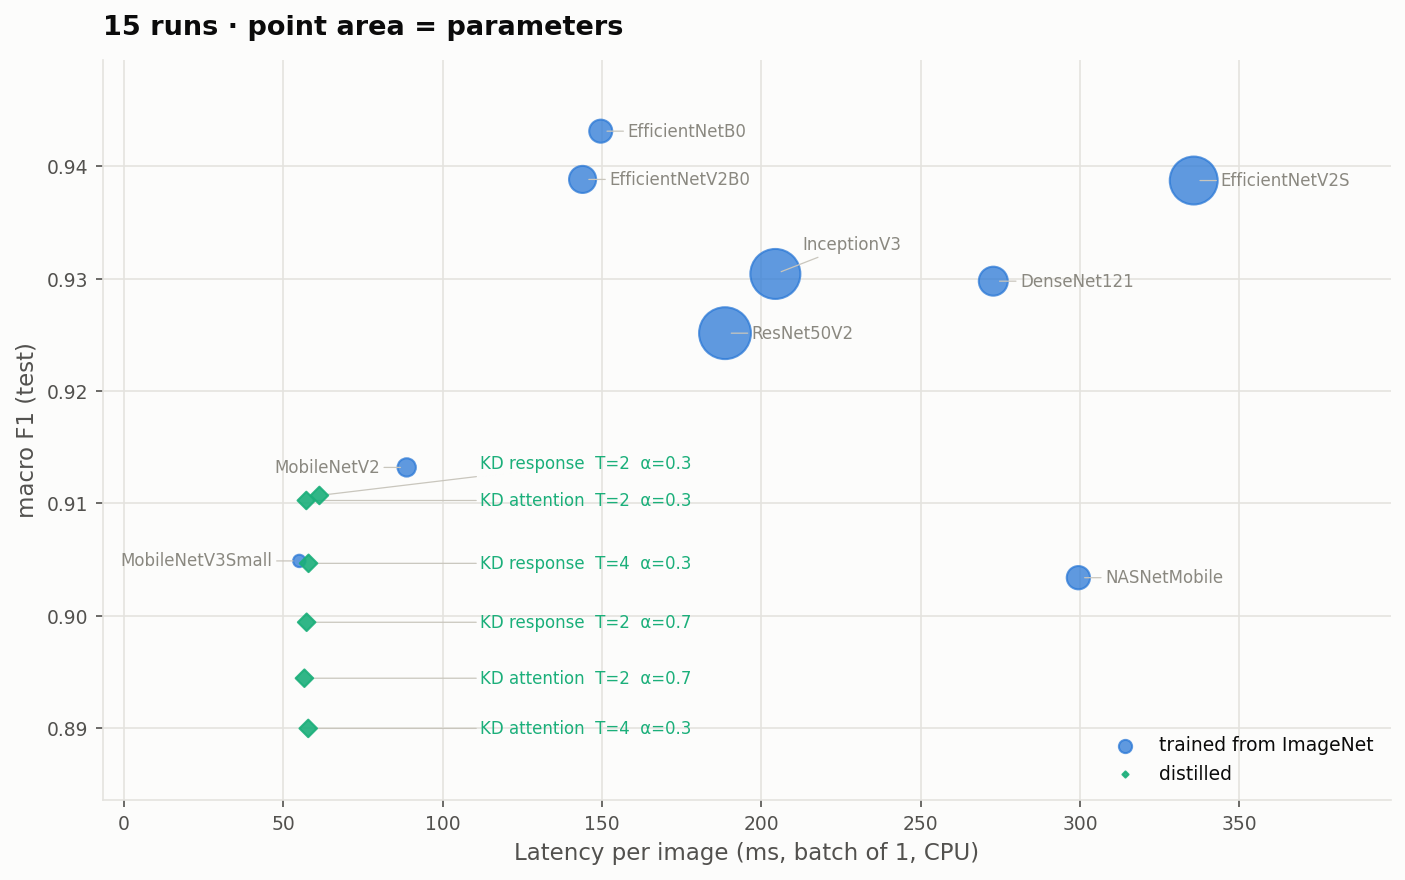

In [23]:
applyStyle()
from scripts.architectures import NOMBRES

fig, ax = plt.subplots(figsize=(9.5, 6))
base = todos[todos["tipo"] == "base"]
destilados = todos[todos["tipo"] == "destilado"].sort_values("test_macro_f1")

ax.scatter(base["latencia_ms"], base["test_macro_f1"], s=base["parametros_M"] * 25,
           color=SERIE_1, alpha=0.75, label="trained from ImageNet", zorder=3)
ax.scatter(destilados["latencia_ms"], destilados["test_macro_f1"],
           s=destilados["parametros_M"] * 25, color=SERIE_3, alpha=0.9,
           marker="D", label="distilled", zorder=4)

rangoX = todos["latencia_ms"].max() - todos["latencia_ms"].min()
rangoY = todos["test_macro_f1"].max() - todos["test_macro_f1"].min()
sangria = rangoX * 0.03
paso = rangoY * 0.062


def anotar(texto, punto, destino, color, ha="left"):
    ax.annotate(texto, punto, xytext=destino, fontsize=8, va="center", ha=ha, color=color,
                arrowprops=dict(arrowstyle="-", linewidth=0.6, color="#c9c6bd",
                                shrinkA=0, shrinkB=3))


# los destilados se amontonan en un mismo punto y solo los distinguen T y alfa:
# sus etiquetas van en una columna alineada a la derecha
columna = destilados["latencia_ms"].max() + sangria * 6
altura = techo = destilados["test_macro_f1"].min()
for _, f in destilados.iterrows():
    altura = max(f["test_macro_f1"], altura)
    variante = {"respuesta": "response", "atencion": "attention"}[f["destilacion"]]
    anotar(f"KD {variante}  T={f['T']:g}  α={f['alfa']:g}",
           (f["latencia_ms"], f["test_macro_f1"]), (columna, altura), SERIE_3)
    techo = altura
    altura += paso

# las bases se rotulan junto a su marcador, a la izquierda cuando chocarian con
# la columna; solo se separan en vertical las que ademas coinciden en latencia
ultimo = {}
for _, f in base.sort_values("test_macro_f1").iterrows():
    y = f["test_macro_f1"]
    for x0, y0 in ultimo.items():
        if abs(f["latencia_ms"] - x0) < rangoX * 0.25 and y - y0 < paso:
            y = y0 + paso
    ultimo[f["latencia_ms"]] = y
    choca = f["latencia_ms"] < columna and y <= techo + paso
    anotar(NOMBRES[f["arquitectura"]], (f["latencia_ms"], f["test_macro_f1"]),
           (f["latencia_ms"] - sangria if choca else f["latencia_ms"] + sangria, y),
           INK_MUTED, "right" if choca else "left")

ax.margins(x=0.22, y=0.12)
ax.set(xlabel="Latency per image (ms, batch of 1, CPU)", ylabel="macro F1 (test)",
       title=f"{len(todos)} runs · point area = parameters")
ax.legend(loc="lower right", frameon=False, fontsize=9, scatterpoints=1, markerscale=0.35)
fig.tight_layout()
fig.savefig(FIGURAS / "calidad_vs_latencia.png", dpi=300, bbox_inches="tight")
plt.show()

## 3 · ¿Sirvió la destilación?

El control es el run sin destilar del mismo estudiante, así que el único
factor que cambia es el docente.

In [16]:
destilados = todos[todos["tipo"] == "destilado"]
assert len(destilados), "sin runs destilados todavía"

comparaciones = []
for _, dest in destilados.iterrows():
    cfg = registro.loadRunConfig(dest["run_id"])
    docente = registro.findRun(cfg["distillation"]["teacher_run_id"])
    descongelado = registro.findRun(dest["run_id"])["finetuning"]
    control = next(r for r in registro.listRuns()
                   if r["architecture"] == dest["arquitectura"]
                   and not r.get("teacher_run_id")
                   and r.get("finetuning") == descongelado
                   and r.get("dataset") == CORPUS)
    comparaciones.append({
        "destilado": dest["run_id"],
        "estudiante": dest["arquitectura"],
        "tipo": cfg["distillation"]["tipo"],
        "finetuning": descongelado,
        "T": cfg["distillation"]["temperatura"],
        "alfa": cfg["distillation"]["alfa"],
        "f1_control": control["test_macro_f1"],
        "f1_destilado": dest["test_macro_f1"],
        "f1_docente": docente["test_macro_f1"],
        "delta": dest["test_macro_f1"] - control["test_macro_f1"],
        "brecha": docente["test_macro_f1"] - control["test_macro_f1"],
        "min_control": control["training_minutes"],
        "min_destilado": dest["minutos"],
    })

resumen = pd.DataFrame(comparaciones)
for _, r in resumen.iterrows():
    signo = "mejora" if r["delta"] > 0 else "empeora"
    print(f"{r['tipo']:12} T={r['T']} alfa={r['alfa']}  {signo} {abs(r['delta']):.4f} de macro-F1")
    print(f"  control {r['f1_control']:.4f} -> destilado {r['f1_destilado']:.4f} "
          f"(docente {r['f1_docente']:.4f}, brecha {r['brecha']:+.4f})")
    print(f"  costo: {r['min_control']:.0f} min -> {r['min_destilado']:.0f} min "
          f"({r['min_destilado']/r['min_control']:.1f}x)")
resumen[["tipo", "finetuning", "T", "alfa", "f1_control", "f1_destilado", "f1_docente", "delta"]]

respuesta    T=2.0 alfa=0.3  mejora 0.0058 de macro-F1
  control 0.9049 -> destilado 0.9107 (docente 0.9431, brecha +0.0383)
  costo: 81 min -> 241 min (3.0x)
atencion     T=2.0 alfa=0.3  mejora 0.0054 de macro-F1
  control 0.9049 -> destilado 0.9102 (docente 0.9431, brecha +0.0383)
  costo: 81 min -> 229 min (2.8x)
respuesta    T=4.0 alfa=0.3  empeora 0.0002 de macro-F1
  control 0.9049 -> destilado 0.9047 (docente 0.9431, brecha +0.0383)
  costo: 81 min -> 257 min (3.2x)
respuesta    T=2.0 alfa=0.7  empeora 0.0055 de macro-F1
  control 0.9049 -> destilado 0.8994 (docente 0.9431, brecha +0.0383)
  costo: 81 min -> 236 min (2.9x)
atencion     T=2.0 alfa=0.7  empeora 0.0104 de macro-F1
  control 0.9049 -> destilado 0.8944 (docente 0.9431, brecha +0.0383)
  costo: 81 min -> 219 min (2.7x)
atencion     T=4.0 alfa=0.3  empeora 0.0149 de macro-F1
  control 0.9049 -> destilado 0.8900 (docente 0.9431, brecha +0.0383)
  costo: 81 min -> 252 min (3.1x)


,tipo,finetuning,T,alfa,f1_control,f1_destilado,f1_docente,delta
0,respuesta,0.3,2.0,0.3,0.904865,0.910695,0.943134,0.005830
1,atencion,0.3,2.0,0.3,0.904865,0.910247,0.943134,0.005382
2,respuesta,0.3,4.0,0.3,0.904865,0.904650,0.943134,-0.000215
3,respuesta,0.3,2.0,0.7,0.904865,0.899403,0.943134,-0.005462
4,atencion,0.3,2.0,0.7,0.904865,0.894421,0.943134,-0.010445
5,atencion,0.3,4.0,0.3,0.904865,0.889951,0.943134,-0.014914


## 4 · ¿La diferencia es distinguible del ruido?

In [17]:
verdad = registro.loadRunMetrics(resumen.iloc[0]["destilado"])["splits"]["test"]["y_true"]

def predicciones(runId):
    prueba = registro.loadRunMetrics(runId)["splits"]["test"]
    assert prueba["y_true"] == verdad, f"{runId} no comparte el orden del test"
    return prueba["y_pred"]

pares = []
for _, r in resumen.iterrows():
    cfg = registro.loadRunConfig(r["destilado"])
    docenteId = cfg["distillation"]["teacher_run_id"]
    controlId = next(x["run_id"] for x in registro.listRuns()
                     if x["architecture"] == r["estudiante"]
                     and not x.get("teacher_run_id")
                     and x.get("finetuning") == r["finetuning"]
                     and x.get("dataset") == CORPUS)
    for etiqueta, a, b in ((f"KD {r['tipo']} vs control", r["destilado"], controlId),
                           ("docente vs control", docenteId, controlId)):
        prueba = evalStats.mcnemar(verdad, predicciones(a), predicciones(b))
        pares.append({"comparacion": etiqueta, "solo_A": prueba["solo_a"],
                      "solo_B": prueba["solo_b"], "p": prueba["p"]})

if len(resumen) > 1:
    a, b = resumen.iloc[0]["destilado"], resumen.iloc[1]["destilado"]
    prueba = evalStats.mcnemar(verdad, predicciones(a), predicciones(b))
    pares.append({"comparacion": f"KD {resumen.iloc[0]['tipo']} vs KD {resumen.iloc[1]['tipo']}",
                  "solo_A": prueba["solo_a"], "solo_B": prueba["solo_b"], "p": prueba["p"]})

pareadas = pd.DataFrame(pares).drop_duplicates("comparacion").reset_index(drop=True)
for _, r in pareadas.iterrows():
    veredicto = "indistinguibles" if r["p"] > 0.05 else "diferencia real"
    print(f"{r['comparacion']:34} {r['solo_A']:4} vs {r['solo_B']:4}  p={r['p']:.2e}  {veredicto}")
pareadas

KD respuesta vs control             140 vs  109  p=5.71e-02  indistinguibles
docente vs control                  266 vs   73  p=6.42e-27  diferencia real
KD atencion vs control              137 vs  109  p=8.50e-02  indistinguibles
KD respuesta vs KD atencion          80 vs   77  p=8.73e-01  indistinguibles


,comparacion,solo_A,solo_B,p
0,KD respuesta vs control,140,109,5.706111e-02
1,docente vs control,266,73,6.419794e-27
2,KD atencion vs control,137,109,8.496007e-02
3,KD respuesta vs KD atencion,80,77,8.732481e-01


## 5 · ¿A qué clases afectó?

La hipótesis del diseño era que la destilación ayudaría sobre todo a las
especies con pocas imágenes.

In [18]:
caso = resumen.iloc[0]        # el destilado con mejor macro-F1
print(f"Diseccionando KD {caso['tipo']} ({caso['destilado']})\n")
mDest = registro.loadRunMetrics(caso["destilado"])["splits"]["test"]
descongelado = registro.findRun(caso["destilado"])["finetuning"]
control = next(r for r in registro.listRuns()
               if r["architecture"] == caso["estudiante"]
               and not r.get("teacher_run_id")
               and r.get("finetuning") == descongelado
               and r.get("dataset") == CORPUS)
mCtrl = registro.loadRunMetrics(control["run_id"])["splits"]["test"]

tamano = {e: len(v["train"]) for e, v in corpus.manifiesto()["reparto"].items()}
clases = mDest["class_names"]
delta = pd.DataFrame({
    "especie": clases,
    "n_train": [tamano[c] for c in clases],
    "delta_f1": [mDest["per_class_f1"][c] - mCtrl["per_class_f1"][c] for c in clases],
}).sort_values("n_train")

corte = len(delta) // 3
tercios = [delta.iloc[:corte], delta.iloc[corte:2 * corte], delta.iloc[2 * corte:]]
for etiqueta, grupo in zip(("escasas", "medias", "abundantes"), tercios):
    print(f"  {etiqueta:11} n_train {grupo['n_train'].min():3.0f}-{grupo['n_train'].max():3.0f}  "
          f"delta medio {grupo['delta_f1'].mean():+.4f}  "
          f"empeoran {(grupo['delta_f1'] < 0).sum()}/{len(grupo)}")
print(f"\n  clases que mejoran: {(delta['delta_f1'] > 0).sum()}/{len(delta)}")
print(f"  correlación delta vs n_train: {delta['n_train'].corr(delta['delta_f1']):+.3f}")

Diseccionando KD respuesta (20261021T203700Z_kd-respuesta-t2-a30-mobilenet-v3-small)

  escasas     n_train 129-172  delta medio +0.0058  empeoran 14/33
  medias      n_train 172-185  delta medio +0.0013  empeoran 10/33
  abundantes  n_train 185-213  delta medio +0.0103  empeoran 8/34

  clases que mejoran: 61/100
  correlación delta vs n_train: +0.071


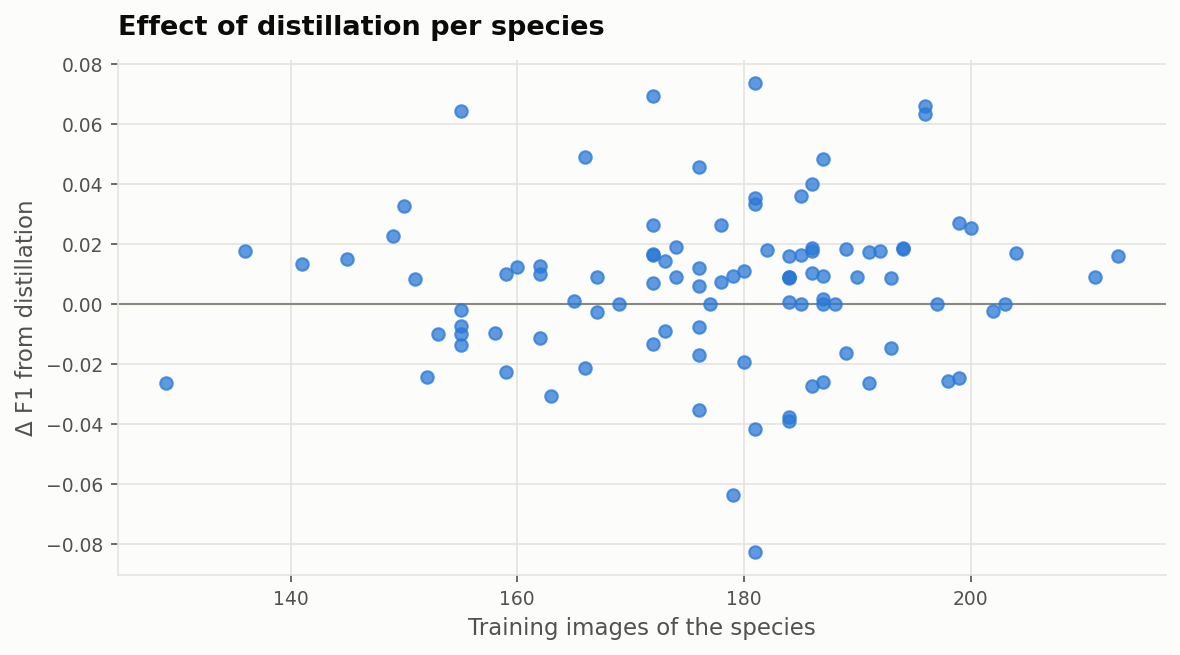

In [19]:
applyStyle()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhline(0, color=INK_MUTED, linewidth=1)
ax.scatter(delta["n_train"], delta["delta_f1"], color=SERIE_1, alpha=0.75, zorder=3)
ax.set(xlabel="Training images of the species", ylabel="Δ F1 from distillation",
       title="Effect of distillation per species")
fig.tight_layout()
plt.show()

## 6 · ¿Redujo la confusión intra-género?

Era la motivación original: los errores se concentran entre especies del mismo
género, y se esperaba que las etiquetas blandas del docente ayudaran ahí.

In [20]:
def intraGenero(metrica):
    mat = np.array(metrica["confusion_matrix"])
    generos = [c.split("_")[0] for c in metrica["class_names"]]
    errores = mat.sum() - np.trace(mat)
    intra = sum(mat[i][j] for i in range(len(generos)) for j in range(len(generos))
                if i != j and generos[i] == generos[j])
    return intra, errores

mDoc = registro.loadRunMetrics(
    registro.loadRunConfig(caso["destilado"])["distillation"]["teacher_run_id"]
)["splits"]["test"]

filas = []
for nombre, m in (("control", mCtrl), ("destilado", mDest), ("docente", mDoc)):
    intra, errores = intraGenero(m)
    filas.append({"modelo": nombre, "errores": int(errores), "intra_genero": int(intra),
                  "fraccion": round(intra / errores, 3)})
pd.DataFrame(filas)

,modelo,errores,intra_genero,fraccion
0,control,473,137,0.290
1,destilado,442,135,0.305
2,docente,280,103,0.368


## 7 · Calidad del docente como fuente de etiquetas blandas

La destilación solo puede transferir lo que el docente sabe. Si su ventaja es
estrecha, o si se equivoca justo donde el problema es difícil, las etiquetas
blandas aportan poco y arrastran su sesgo.

In [21]:
yt, yp = np.array(mDoc["y_true"]), np.array(mDoc["y_pred"])
intraDoc, errDoc = intraGenero(mDoc)
intraCtrl, errCtrl = intraGenero(mCtrl)

print(f"  el docente falla en {(yt != yp).sum()}/{len(yt)} imágenes de test ({(yt != yp).mean():.1%})")
print(f"  ventaja del docente sobre el estudiante: {caso['brecha']:+.4f} de macro-F1")
print(f"  de sus errores, {intraDoc/errDoc:.1%} son intra-género, "
      f"contra {intraCtrl/errCtrl:.1%} del estudiante sin destilar")

  el docente falla en 280/5057 imágenes de test (5.5%)
  ventaja del docente sobre el estudiante: +0.0383 de macro-F1
  de sus errores, 36.8% son intra-género, contra 29.0% del estudiante sin destilar


## 8 · El modelo que se despliega

`1. Entrenamiento/Seleccion` elige el estudiante **del que parte la destilación**, y por eso no puede mirar los destilados. Aquí sí están todos, así que es donde se decide qué sirve el sitio: el mejor macro-F1 de validación entre los runs que caben en el presupuesto de descarga, destilados incluidos. Se escribe en `desplegado.json` y no en `student.json`, que debe seguir apuntando al punto de partida de la destilación para no destilar de un destilado.

In [22]:
PRESUPUESTO_MB = 8.0        # el mismo de 1. Entrenamiento/Seleccion

candidatos = todos[todos["pesos_MB"] <= PRESUPUESTO_MB].sort_values(
    "validate_macro_f1", ascending=False)
if candidatos.empty:
    raise ValueError(f"Ningún run cabe en {PRESUPUESTO_MB} MB")

elegido = candidatos.iloc[0]
destilacion = registro.loadRunConfig(elegido["run_id"]).get("distillation") or {}

registro.writeJson(registro.OUTPUTS_DIR / "desplegado.json", {
    "run_id": elegido["run_id"],
    "architecture": elegido["arquitectura"],
    "dataset": CORPUS,
    "destilacion": destilacion.get("tipo"),
    "temperatura": destilacion.get("temperatura"),
    "alfa": destilacion.get("alfa"),
    "test_accuracy": float(elegido["test_accuracy"]),
    "test_macro_f1": float(elegido["test_macro_f1"]),
    "validate_macro_f1": float(elegido["validate_macro_f1"]),
    "pesos_MB": float(elegido["pesos_MB"]),
    "latencia_ms": float(elegido["latencia_ms"]),
    "presupuesto_MB": PRESUPUESTO_MB,
})

etiqueta = f"KD {destilacion['tipo']}" if destilacion else "sin destilar"
print(f"Desplegado: {elegido['arquitectura']} ({etiqueta}) · macro-F1 "
      f"{elegido['test_macro_f1']:.4f} en test · {elegido['pesos_MB']:.1f} MB")
print(f"{len(candidatos)} de {len(todos)} runs caben en {PRESUPUESTO_MB:.0f} MB\n")
print(candidatos[["arquitectura", "tipo", "destilacion", "validate_macro_f1",
                  "test_macro_f1", "pesos_MB"]].to_string(index=False))

Desplegado: mobilenet_v3_small (KD respuesta) · macro-F1 0.9107 en test · 5.7 MB
7 de 15 runs caben en 8 MB

      arquitectura      tipo destilacion  validate_macro_f1  test_macro_f1  pesos_MB
mobilenet_v3_small destilado   respuesta           0.905694       0.910695       5.7
mobilenet_v3_small destilado    atencion           0.905260       0.910247       5.7
mobilenet_v3_small      base                       0.903339       0.904865       5.7
mobilenet_v3_small destilado   respuesta           0.901423       0.904650       5.7
mobilenet_v3_small destilado   respuesta           0.897161       0.899403       5.7
mobilenet_v3_small destilado    atencion           0.896282       0.894421       5.7
mobilenet_v3_small destilado    atencion           0.890375       0.889951       5.7
